In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [6]:


df = pd.read_csv("../data/Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (7043, 21)

Column Names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn   

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Churn"].value_counts())

print("\nTarget Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Records:
0

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)


df = df.drop(columns=["customerID"])


X = df.drop(columns=["Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0})


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [10]:
eda_df = X_train.copy()
eda_df["Churn"] = y_train

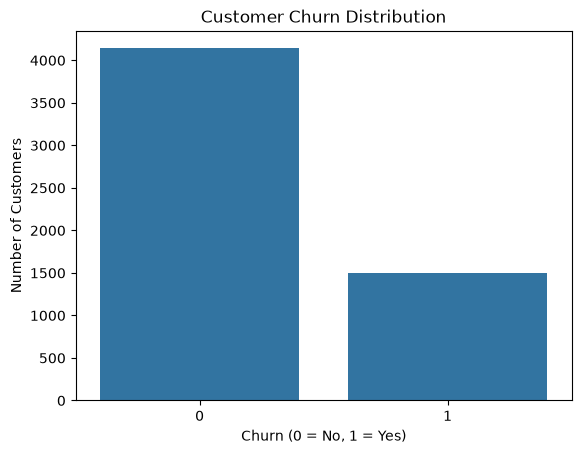

In [11]:
sns.countplot(data=eda_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

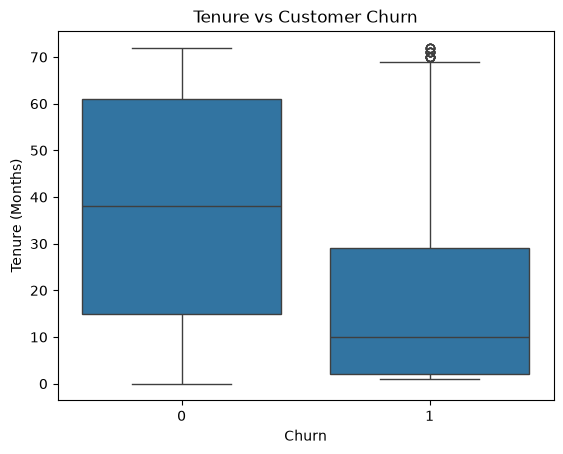

In [12]:
sns.boxplot(data=eda_df, x="Churn", y="tenure")

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

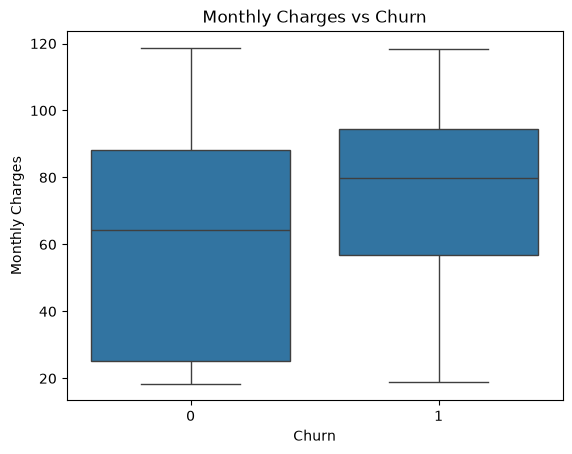

In [13]:
sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

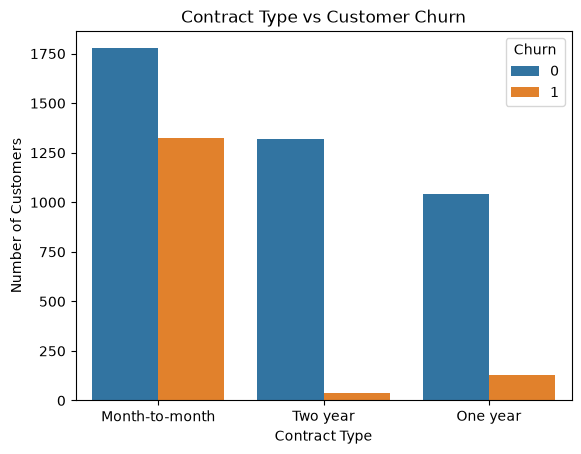

In [14]:
sns.countplot(
    data=eda_df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

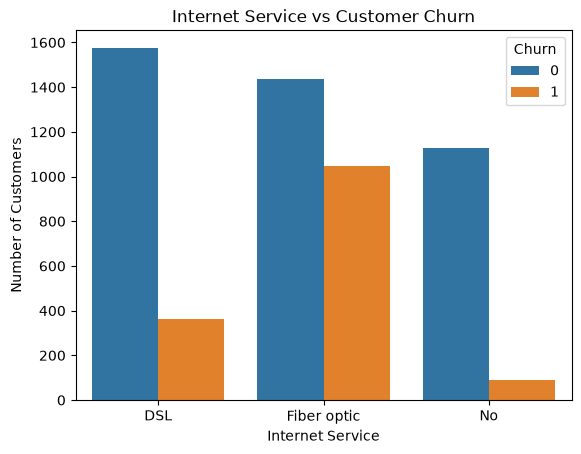

In [15]:
sns.countplot(
    data=eda_df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()


def create_features(data):

    data = data.copy()

    
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Medium", "Long", "Very Long"]
    )

    
    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    data["total_services"] = (
        data[service_columns] == "Yes"
    ).sum(axis=1)

    data["avg_spend_per_month"] = np.where(
        data["tenure"] > 0,
        data["TotalCharges"] / data["tenure"],
        data["MonthlyCharges"]
    )

    data["has_family"] = (
        (data["Partner"] == "Yes") |
        (data["Dependents"] == "Yes")
    ).astype(int)

    data["is_long_contract"] = (
        data["Contract"].isin(["One year", "Two year"])
    ).astype(int)

    return data


X_train_fe = create_features(X_train_fe)
X_test_fe = create_features(X_test_fe)

print("Feature engineering completed!")

print("Original number of training features:", X_train.shape[1])
print("New number of training features:", X_train_fe.shape[1])

display(X_train_fe.head())

Feature engineering completed!
Original number of training features: 19
New number of training features: 24


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,total_services,avg_spend_per_month,has_family,is_long_contract
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Month-to-month,No,Electronic check,49.20,1701.65,Long,3,48.618571,0,0
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,Month-to-month,No,Mailed check,75.10,1151.55,Medium,2,76.770000,1,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,Two year,No,Mailed check,40.55,590.35,Medium,3,45.411538,1,1
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Two year,Yes,Credit card (automatic),73.50,1905.70,Long,5,73.296154,1,1
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,Month-to-month,No,Electronic check,44.55,44.55,New,1,44.550000,1,0


week 3 day 5 part 2 


In [24]:
print("Training data shape:", X_train_fe.shape)
print("Testing data shape:", X_test_fe.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5634, 19)
Testing data shape: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [25]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, f1_score

In [26]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale positive weight:", scale_pos_weight)

Negative samples: 4139
Positive samples: 1495
Scale positive weight: 2.768561872909699


In [29]:
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in ["preprocess", "transform", "column"]):
        print(name, ":", type(obj).__name__)

service_columns : list


In [30]:
for name, obj in list(globals().items()):
    if hasattr(obj, "transformers"):
        print("Found:", name)
        print(obj.transformers)

In [31]:
print([name for name in globals() if "column" in name.lower() or "pre" in name.lower()])

['service_columns']


In [32]:
print("Training data columns:")
print(X_train_fe.columns.tolist())

print("\nData types:")
print(X_train_fe.dtypes)

Training data columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [33]:
def create_features(data):
    data = data.copy()

    # Feature 1: Group customers by tenure
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Medium", "Long", "Very Long"]
    )

    # Feature 2: Count the services used by each customer
    data["total_services"] = (
        data[service_columns] == "Yes"
    ).sum(axis=1)

    # Feature 3: Average monthly spending
    data["avg_spend_per_month"] = np.where(
        data["tenure"] > 0,
        data["TotalCharges"] / data["tenure"],
        data["MonthlyCharges"]
    )

    # Feature 4: Check whether customer has family
    data["has_family"] = (
        (data["Partner"] == "Yes") |
        (data["Dependents"] == "Yes")
    ).astype(int)

    # Feature 5: Check long-term contract
    data["is_long_contract"] = (
        data["Contract"].isin(["One year", "Two year"])
    ).astype(int)

    return data

In [34]:
X_train_fe = create_features(X_train_fe)
X_test_fe = create_features(X_test_fe)

print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

Training shape: (5634, 24)
Testing shape: (1409, 24)


In [35]:
new_features = [
    "tenure_group",
    "total_services",
    "avg_spend_per_month",
    "has_family",
    "is_long_contract"
]

display(X_train_fe[new_features].head())

,tenure_group,total_services,avg_spend_per_month,has_family,is_long_contract
3738,Long,3,48.618571,0,0
3151,Medium,2,76.770000,1,0
4860,Medium,3,45.411538,1,1
3867,Long,5,73.296154,1,1
3810,New,1,44.550000,1,0


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [37]:
numeric_features = X_train_fe.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_fe.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'total_services', 'avg_spend_per_month', 'has_family', 'is_long_contract']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


In [38]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [39]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [40]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [41]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges', 'total_services',
                                  'avg_spend_per_month', 'has_family',
                                  'is_long_contract']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneServ

In [42]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 2.768561872909699


In [43]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [44]:
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

In [45]:
xgb_pipeline.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['gender','SeniorCitizen','Partner',...,'avg_spend_per_month','has_family', 'is_long_contract']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

In [46]:
print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [47]:
from sklearn.model_selection import cross_validate

In [48]:
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train_fe,
    y_train,
    cv=5,
    scoring={
        "roc_auc": "roc_auc",
        "f1": "f1"
    },
    n_jobs=-1
)

In [49]:
print("Mean ROC-AUC:", xgb_cv["test_roc_auc"].mean())
print("Mean F1:", xgb_cv["test_f1"].mean())

Mean ROC-AUC: 0.8399609124738443
Mean F1: 0.6301647695811857


In [50]:
for name in globals():
    if any(word in name.lower() for word in [
        "logistic", "lr", "random", "forest", "rf"
    ]):
        print(name)

In [51]:
print(list(globals().keys()))

['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__vsc_ipynb_file__', '_i', '_ii', '_iii', '_i1', 'url', '_i2', '_i3', '_i4', '_i5', 'pd', 'np', 'plt', 'sns', 'train_test_split', '_i6', 'df', '_6', '_i7', '_7', '_i8', '_i9', 'X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', '_i10', 'eda_df', '_i11', '_i12', '_i13', '_i14', '_i15', '_i16', 'X_train_fe', 'X_test_fe', 'create_features', '_i17', '_i18', '_i19', 'service_columns', '_i20', '_i21', '_i22', '_i23', '_i24', '_i25', 'XGBClassifier', 'Pipeline', 'roc_auc_score', 'f1_score', '_i26', 'negative_count', 'positive_count', 'scale_pos_weight', '_i27', '_i28', '_i29', 'name', 'obj', '_i30', '_i31', '_i32', '_i33', '_i34', '_i35', 'new_features', '_i36', 'ColumnTransformer', 'OneHotEncoder', 'StandardScaler', 'SimpleImputer', '_i37', 'numeric_features', 'categorical_features', '_i38', 'numeric_transf

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Logistic Regression
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Random Forest
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Logistic Regression and Random Forest pipelines created!")

Logistic Regression and Random Forest pipelines created!


In [53]:
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

results = []

for name, model in models.items():

    print("Training:", name)

    scores = cross_validate(
        model,
        X_train_fe,
        y_train,
        cv=5,
        scoring={
            "roc_auc": "roc_auc",
            "f1": "f1"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 Score": scores["test_f1"].mean()
    })

print("Cross-validation completed!")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost
Cross-validation completed!


In [54]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  ROC-AUC  F1 Score
Logistic Regression 0.845644  0.626878
            XGBoost 0.839361  0.626537
      Random Forest 0.829228  0.606998


In [55]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

# Parameters to test
lr_parameters = {
    "classifier__C": loguniform(0.001, 100)
}

# Randomized Search
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_parameters,
    n_iter=10,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=1
)

# Train and tune using training data only
lr_search.fit(X_train_fe, y_train)

print("Best Logistic Regression Parameters:")
print(lr_search.best_params_)

print("\nBest Logistic Regression ROC-AUC:")
print(lr_search.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': np.float64(56.69849511478853)}

Best Logistic Regression ROC-AUC:
0.8458771926688394


In [56]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Parameters to test
xgb_parameters = {
    "classifier__n_estimators": randint(100, 500),
    "classifier__max_depth": randint(3, 8),
    "classifier__learning_rate": uniform(0.01, 0.19),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__colsample_bytree": uniform(0.7, 0.3),
    "classifier__min_child_weight": randint(1, 8)
}

# Randomized Search
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameters,
    n_iter=10,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Train and tune
xgb_search.fit(X_train_fe, y_train)

print("\nBest XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest XGBoost ROC-AUC:")
print(xgb_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best XGBoost Parameters:
{'classifier__colsample_bytree': np.float64(0.7467983561008608), 'classifier__learning_rate': np.float64(0.021035886311957897), 'classifier__max_depth': 7, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 459, 'classifier__subsample': np.float64(0.9124217733388136)}

Best XGBoost ROC-AUC:
0.8360375346257655


In [57]:
tuned_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": lr_search.best_score_
    },
    {
        "Model": "XGBoost",
        "ROC-AUC": xgb_search.best_score_
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": results_df.loc[
            results_df["Model"] == "Random Forest",
            "ROC-AUC"
        ].iloc[0]
    }
])

print(tuned_results.sort_values(
    by="ROC-AUC",
    ascending=False
).to_string(index=False))

              Model  ROC-AUC
Logistic Regression 0.845877
            XGBoost 0.836038
      Random Forest 0.829228


In [58]:
from sklearn.model_selection import cross_validate

final_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
    "Random Forest": rf_pipeline
}

final_results = []

for name, model in final_models.items():

    scores = cross_validate(
        model,
        X_train_fe,
        y_train,
        cv=5,
        scoring={
            "roc_auc": "roc_auc",
            "f1": "f1"
        },
        n_jobs=1
    )

    final_results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 Score": scores["test_f1"].mean()
    })

final_results_df = pd.DataFrame(final_results)

print(final_results_df.to_string(index=False))

              Model  ROC-AUC  F1 Score
Logistic Regression 0.845877  0.627575
            XGBoost 0.836038  0.622868
      Random Forest 0.829228  0.606998


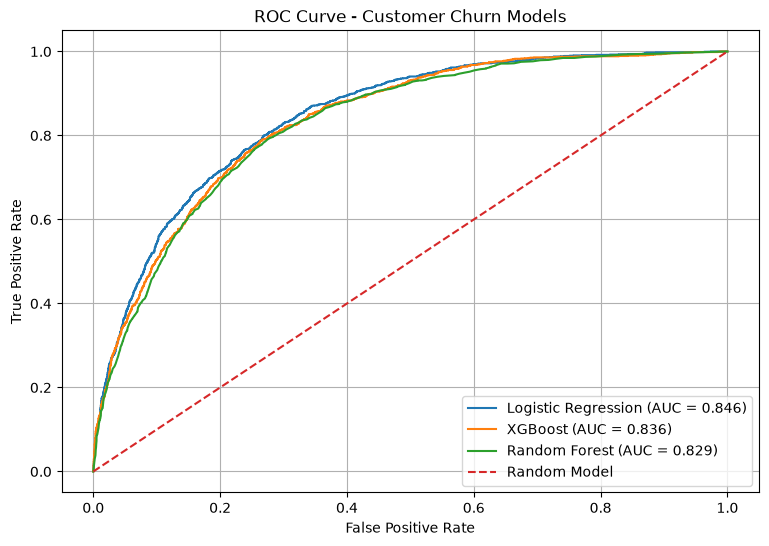

In [59]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 6))

for name, model in final_models.items():

    # Get cross-validated probabilities
    probabilities = cross_val_predict(
        model,
        X_train_fe,
        y_train,
        cv=5,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_train,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

# Random guessing reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Models")
plt.legend()
plt.grid()
plt.show()

In [60]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score
import numpy as np

# Get cross-validated churn probabilities
lr_probabilities = cross_val_predict(
    lr_search.best_estimator_,
    X_train_fe,
    y_train,
    cv=5,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Find a threshold that achieves at least 75% recall
thresholds = np.arange(0.10, 0.71, 0.01)

for threshold in thresholds:
    predictions = (lr_probabilities >= threshold).astype(int)

    recall = recall_score(y_train, predictions)

    if recall >= 0.75:
        print("Selected Threshold:", round(threshold, 2))
        print("Recall:", round(recall, 4))
        break

Selected Threshold: 0.1
Recall: 0.9806


In [61]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold = 0.10

threshold_predictions = (
    lr_probabilities >= threshold
).astype(int)

print("Threshold:", threshold)

print("Precision:",
      precision_score(y_train, threshold_predictions))

print("Recall:",
      recall_score(y_train, threshold_predictions))

print("F1 Score:",
      f1_score(y_train, threshold_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, threshold_predictions))

Threshold: 0.1
Precision: 0.33911635438352994
Recall: 0.9806020066889632
F1 Score: 0.5039532485390168

Confusion Matrix:
[[1282 2857]
 [  29 1466]]


In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:

    predictions = (
        lr_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1 Score": f1_score(y_train, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1 Score
       0.1      0.339   0.981     0.504
       0.2      0.388   0.953     0.552
       0.3      0.426   0.919     0.582
       0.4      0.470   0.874     0.611
       0.5      0.518   0.794     0.627


In [63]:
from sklearn.inspection import permutation_importance

# Use the best tuned Logistic Regression model
best_model = lr_search.best_estimator_

# Calculate permutation importance using training data
importance = permutation_importance(
    best_model,
    X_train_fe,
    y_train,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": X_train_fe.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

             Feature  Importance
7    InternetService    0.163153
4             tenure    0.140456
17    MonthlyCharges    0.129081
20    total_services    0.052952
23  is_long_contract    0.024751
13   StreamingMovies    0.013998
12       StreamingTV    0.013175
8     OnlineSecurity    0.012644
11       TechSupport    0.010291
14          Contract    0.007156


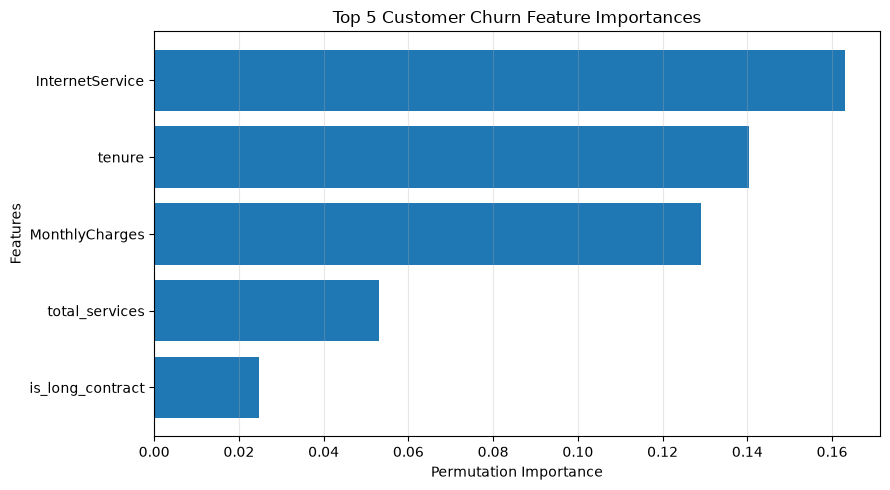

In [64]:
import matplotlib.pyplot as plt

top_features = importance_df.head(5).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Top 5 Customer Churn Feature Importances")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    confusion_matrix,
    classification_report
)

best_model = lr_search.best_estimator_

# Predict probabilities on the untouched test set
test_probabilities = best_model.predict_proba(X_test_fe)[:, 1]

# Apply selected threshold
test_predictions = (test_probabilities >= 0.50).astype(int)

print("Test ROC-AUC:", roc_auc_score(y_test, test_probabilities))
print("Test F1 Score:", f1_score(y_test, test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Test ROC-AUC: 0.8407347128574749
Test F1 Score: 0.6147455867082036

Confusion Matrix:
[[742 293]
 [ 78 296]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [66]:
import joblib
from pathlib import Path

# Create models folder if it doesn't exist
Path("models").mkdir(exist_ok=True)

# Save trained model
joblib.dump(best_model, "models/churn_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [67]:
print(service_columns)

['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


In [68]:
import pandas as pd
import numpy as np
import joblib

# Load the trained model
model = joblib.load("models/churn_model.joblib")

# Features used for service count
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Selected prediction threshold
THRESHOLD = 0.50

print("Churn prediction model loaded successfully!")

Churn prediction model loaded successfully!


In [69]:
def create_features(data):
    data = data.copy()

    # Convert TotalCharges into numeric values
    data["TotalCharges"] = pd.to_numeric(
        data["TotalCharges"], errors="coerce"
    )

    # 1. Group customers based on tenure
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Medium", "Long", "Very Long"]
    )

    # 2. Count subscribed services
    data["total_services"] = (
        data[service_columns] == "Yes"
    ).sum(axis=1)

    # 3. Calculate average monthly spending
    data["avg_spend_per_month"] = np.where(
        data["tenure"] > 0,
        data["TotalCharges"] / data["tenure"],
        data["MonthlyCharges"]
    )

    # 4. Check whether customer has family
    data["has_family"] = (
        (data["Partner"] == "Yes") |
        (data["Dependents"] == "Yes")
    ).astype(int)

    # 5. Check whether customer has a long-term contract
    data["is_long_contract"] = (
        data["Contract"].isin(["One year", "Two year"])
    ).astype(int)

    return data